# **Lab 5: Feature Analysis of the Second-Hand Car Price Dataset**
**AIM**

To explore the structure, statistical characteristics, distributions, and relationships among features in the Second-Hand Car Price Prediction dataset.

**ALGORITHM**

1. Load the dataset.
2. Display records and dataset information.
3. Identify numerical and categorical columns.
4. Check missing and duplicate values.
5. Examine the target-price distribution.
6. Analyze price by brand, fuel type, transmission, and year.
7. Construct a correlation matrix for numerical features.
8. Identify the most influential features.



Shape: (100, 13)


,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,1,Toyota,Corolla,2018,50000,Petrol,Manual,First,15,1498,108,5,800000
1,2,Honda,Civic,2019,40000,Petrol,Automatic,Second,17,1597,140,5,1000000
2,3,Ford,Mustang,2017,20000,Petrol,Automatic,First,10,4951,395,4,2500000
3,4,Maruti,Swift,2020,30000,Diesel,Manual,Third,23,1248,74,5,600000
4,5,Hyundai,Sonata,2016,60000,Diesel,Automatic,Second,18,1999,194,5,850000



Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Car_ID             100 non-null    int64 
 1   Brand              100 non-null    object
 2   Model              100 non-null    object
 3   Year               100 non-null    int64 
 4   Kilometers_Driven  100 non-null    int64 
 5   Fuel_Type          100 non-null    object
 6   Transmission       100 non-null    object
 7   Owner_Type         100 non-null    object
 8   Mileage            100 non-null    int64 
 9   Engine             100 non-null    int64 
 10  Power              100 non-null    int64 
 11  Seats              100 non-null    int64 
 12  Price              100 non-null    int64 
dtypes: int64(8), object(5)
memory usage: 10.3+ KB

Missing values:
Car_ID               0
Brand                0
Model                0
Year                 0
Kilometers_Driven

,Car_ID,Brand,Model,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
count,100.000000,100,100,100.00000,100.000000,100,100,100,100.000000,100.000000,100.000000,100.000000,1.000000e+02
unique,NaN,11,58,NaN,NaN,2,2,3,NaN,NaN,NaN,NaN,NaN
top,NaN,Ford,Mustang,NaN,NaN,Petrol,Automatic,First,NaN,NaN,NaN,NaN,NaN
freq,NaN,11,3,NaN,NaN,52,57,44,NaN,NaN,NaN,NaN,NaN
mean,50.500000,NaN,NaN,2018.39000,28150.000000,NaN,NaN,NaN,17.210000,1855.230000,158.130000,5.230000,1.574000e+06
std,29.011492,NaN,NaN,1.17116,9121.375716,NaN,NaN,NaN,3.309902,631.311475,76.968137,0.750151,1.000265e+06
min,1.000000,NaN,NaN,2016.00000,10000.000000,NaN,NaN,NaN,10.000000,999.000000,68.000000,4.000000,4.500000e+05
25%,25.750000,NaN,NaN,2017.75000,22000.000000,NaN,NaN,NaN,15.000000,1462.000000,103.000000,5.000000,7.000000e+05
50%,50.500000,NaN,NaN,2018.00000,27000.000000,NaN,NaN,NaN,17.000000,1774.000000,148.000000,5.000000,1.300000e+06
75%,75.250000,NaN,NaN,2019.00000,32000.000000,NaN,NaN,NaN,19.000000,2143.000000,187.000000,5.000000,2.500000e+06



Column names:
['Car_ID', 'Brand', 'Model', 'Year', 'Kilometers_Driven', 'Fuel_Type', 'Transmission', 'Owner_Type', 'Mileage', 'Engine', 'Power', 'Seats', 'Price']


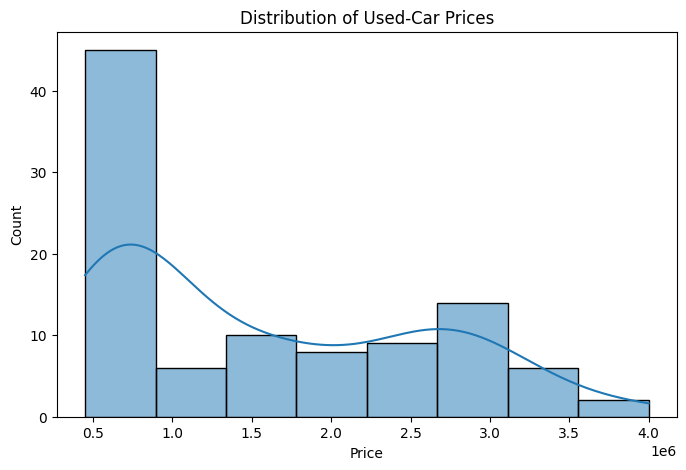

Categorical features:
['Brand', 'Model', 'Fuel_Type', 'Transmission', 'Owner_Type']
Numerical features:
['Car_ID', 'Year', 'Kilometers_Driven', 'Mileage', 'Engine', 'Power', 'Seats', 'Price']


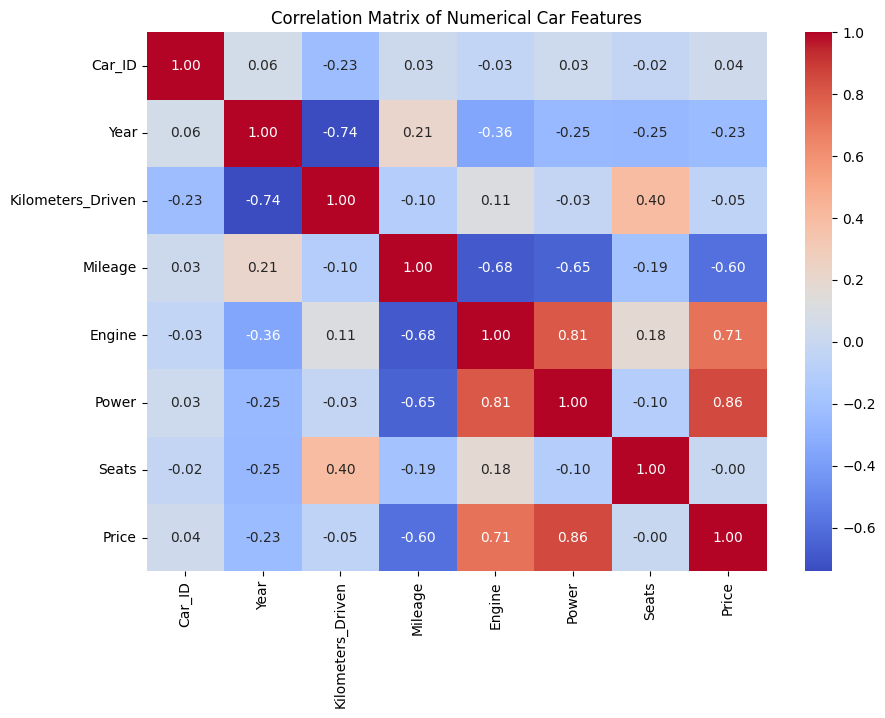

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

car_df = pd.read_csv("cars.csv")

print("Shape:", car_df.shape)
display(car_df.head())

print("\nInformation:")
car_df.info()

print("\nMissing values:")
print(car_df.isnull().sum())

print("\nDescriptive statistics:")
display(car_df.describe(include="all"))

print("\nColumn names:")
print(car_df.columns.tolist())

target_car = "Price"

# Price distribution
plt.figure(figsize=(8, 5))
sns.histplot(car_df[target_car].dropna(), kde=True)
plt.title("Distribution of Used-Car Prices")
plt.show()

# Feature types
categorical_columns = car_df.select_dtypes(include=["object", "category"]).columns
print("Categorical features:")
print(list(categorical_columns))

numerical_columns = car_df.select_dtypes(include=["int64", "float64"]).columns
print("Numerical features:")
print(list(numerical_columns))

# Price by fuel type, if available
if "fuel" in car_df.columns:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=car_df, x="fuel", y=target_car, hue="fuel", legend=False)
    plt.xticks(rotation=30)
    plt.title("Car Price by Fuel Type")
    plt.show()

# Price by transmission, if available
if "transmission" in car_df.columns:
    plt.figure(figsize=(7, 5))
    sns.boxplot(data=car_df, x="transmission", y=target_car, hue="transmission", legend=False)
    plt.title("Car Price by Transmission")
    plt.show()

# Correlation heatmap
plt.figure(figsize=(10, 7))
corr = car_df.select_dtypes(include="number").corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numerical Car Features")
plt.show()

# **Lab 6: Preprocessing the Second-Hand Car Dataset**
**AIM**

To perform missing-data analysis, duplicate detection, and outlier treatment on the second-hand car dataset.

**ALGORITHM**

1. Load the car dataset.
2. Remove duplicate rows.
3. Inspect missing values.
4. Separate numerical and categorical features.
5. Fill missing numerical values with the median.
6. Fill missing categorical values with the mode.
7. Detect numerical outliers using the IQR method.
8. Cap extreme observations.
9. Encode categorical features during model training.
10. Save the cleaned dataset.




Duplicate rows: 0
Car_ID               0
Brand                0
Model                0
Year                 0
Kilometers_Driven    0
Fuel_Type            0
Transmission         0
Owner_Type           0
Mileage              0
Engine               0
Power                0
Seats                0
Price                0
dtype: int64


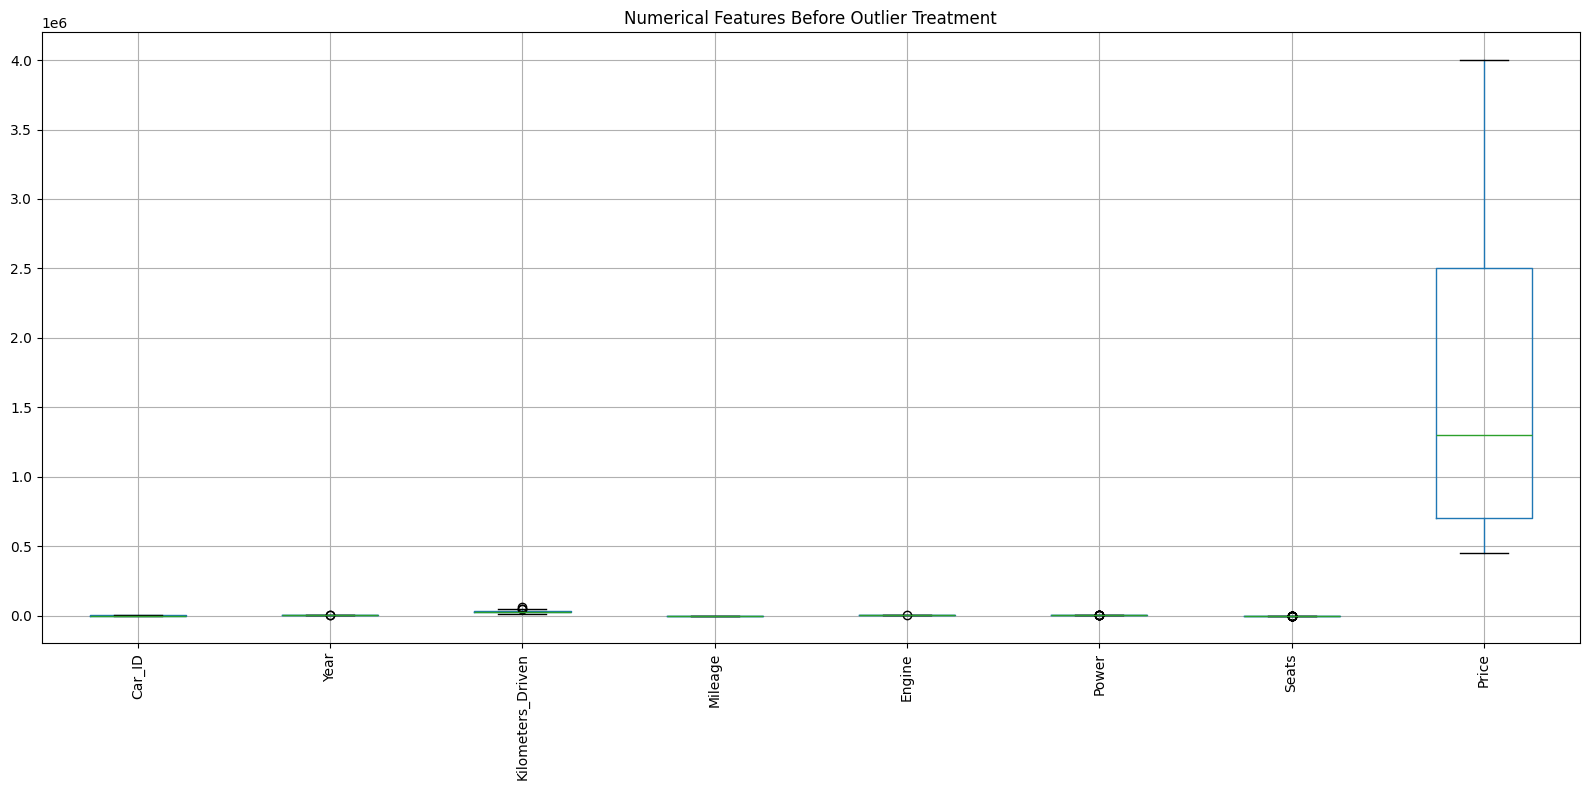

Remaining missing values:
0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

car_df = pd.read_csv("cars.csv")

target_car = "Price"

print("Duplicate rows:", car_df.duplicated().sum())
print(car_df.isnull().sum())

car_df = car_df.drop_duplicates().copy()

numeric_columns = car_df.select_dtypes(include=np.number).columns
categorical_columns = car_df.select_dtypes(include=["object", "category"]).columns

# Fill missing values
for column in numeric_columns:
    car_df[column] = car_df[column].fillna(car_df[column].median())

for column in categorical_columns:
    if car_df[column].notna().any():
        car_df[column] = car_df[column].fillna(car_df[column].mode()[0])

# Box plots before outlier treatment
car_df[numeric_columns].boxplot(figsize=(16, 8), rot=90)
plt.title("Numerical Features Before Outlier Treatment")
plt.tight_layout()
plt.show()

# IQR-based outlier capping
for column in numeric_columns:
    q1 = car_df[column].quantile(0.25)
    q3 = car_df[column].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    car_df[column] = car_df[column].clip(lower=lower_bound, upper=upper_bound)

print("Remaining missing values:")
print(car_df.isnull().sum().sum())

car_df.to_csv("car_price_cleaned.csv", index=False)

# **Lab 7: Feature Engineering and Car Price Prediction**
**AIM**

To create meaningful new features and build machine learning regression models for predicting second-hand car prices.

**ALGORITHM**

1. Load the cleaned car dataset.
2. Identify the target price column.
3. Create vehicle age.
4. Create additional meaningful features.
5. Separate features and target.
6. Identify numerical and categorical columns.
7. Impute missing values.
8. Encode categorical variables.
9. Split the data into training and testing sets.
10. Train regression models.
11. Generate predicted prices.


In [ ]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

car_df = pd.read_csv("car_price_cleaned.csv")
target_car = "Price"

# Feature engineering
current_year = pd.Timestamp.now().year

if "year" in car_df.columns:
    car_df["vehicle_age"] = current_year - car_df["year"]

if "km_driven" in car_df.columns and "vehicle_age" in car_df.columns:
    car_df["km_per_year"] = car_df["km_driven"] / (car_df["vehicle_age"] + 1)

# Remove rows with missing target
car_df = car_df.dropna(subset=[target_car])

X = car_df.drop(target_car, axis=1)
y = car_df[target_car]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer([
    ("numerical", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=12),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

car_predictions = {}

for name, regressor in models.items():
    model = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])
    model.fit(X_train, y_train)
    car_predictions[name] = model.predict(X_test)
    print(name, "training completed")

Linear Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


# **Lab 8: Accuracy and Comparative Analysis of Car Price Models**
**AIM**

To evaluate the regression models using error measures and compare their predictive performance.

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,167534.826680,8.619642e+10,293592.263157,0.894606
3,Gradient Boosting,176561.268792,1.209987e+11,347848.672615,0.852053
2,Random Forest,207837.500000,1.478761e+11,384546.603970,0.819189
1,Decision Tree,192500.000000,1.773750e+11,421159.114825,0.783120


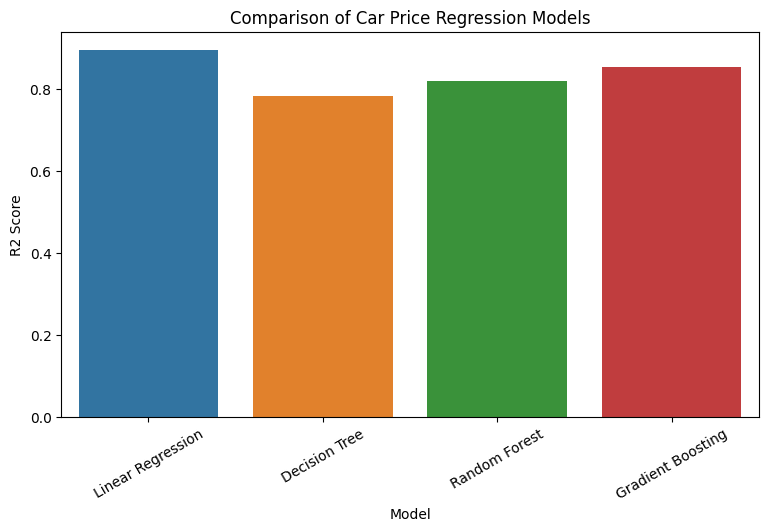

Best regression model: Linear Regression


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

car_results = []

for name, prediction in car_predictions.items():
    mae = mean_absolute_error(y_test, prediction)
    mse = mean_squared_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    car_results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

car_results_df = pd.DataFrame(car_results)
display(car_results_df.sort_values("R2 Score", ascending=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=car_results_df, x="Model", y="R2 Score", hue="Model", legend=False)
plt.xticks(rotation=30)
plt.title("Comparison of Car Price Regression Models")
plt.show()

best_car_model = car_results_df.loc[car_results_df["R2 Score"].idxmax(), "Model"]

print("Best regression model:", best_car_model)

# **Lab 9: Actual Price versus Predicted Price Scatter Plot**
**AIM**

To visualize the variation between actual car prices and predicted car prices.

**ALGORITHM**

1. Select the best-performing regression model.
2. Obtain predictions for the test set.
3. Plot actual prices on the x-axis.
4. Plot predicted prices on the y-axis.
5. Draw a reference line (y=x).
6. Interpret the distance of points from the reference line.



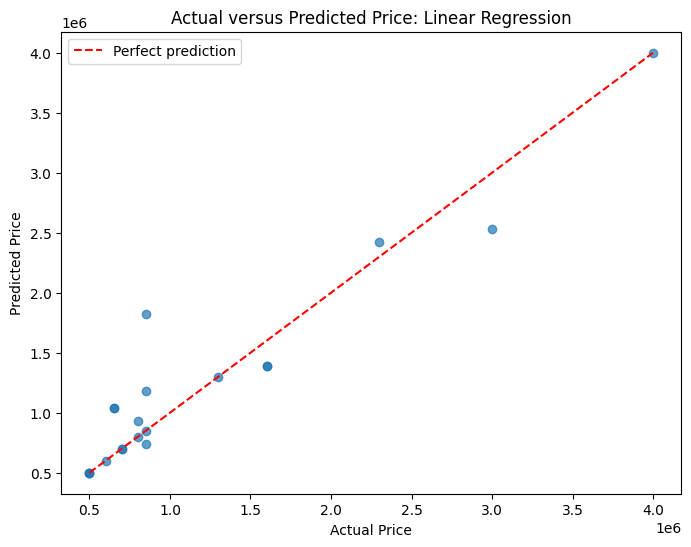

In [ ]:
import matplotlib.pyplot as plt

best_model_name = car_results_df.loc[car_results_df["R2 Score"].idxmax(), "Model"]

actual = y_test.values
predicted = car_predictions[best_model_name]

plt.figure(figsize=(8, 6))
plt.scatter(actual, predicted, alpha=0.7)

minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title(f"Actual versus Predicted Price: {best_model_name}")
plt.legend()
plt.show()